# Workshop 1 - Sturdy-Octo-Disco-Adding-Sunglasses-for-a-Cool-New-Look
## Name:SHEETAL R
## Reg No: 212223230206

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

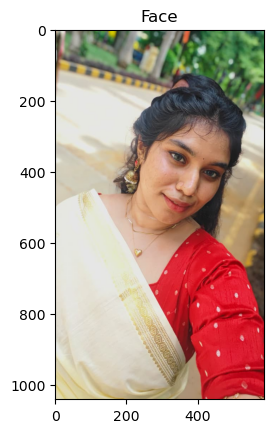

In [4]:
# Load the Face Image
faceImage = cv2.imread('sheetal.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [5]:
faceImage.shape

(1040, 587, 3)

In [6]:
#resized_faceImage.shape
faceImage.shape

(1040, 587, 3)

Text(0.5, 1.0, 'glassPNG')

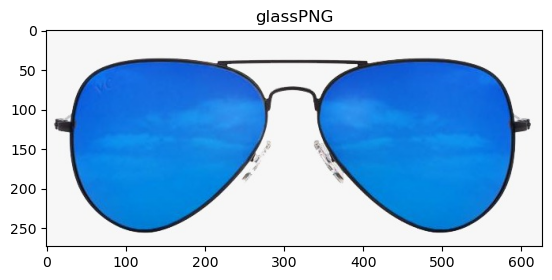

In [7]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('glass.jpg',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [8]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(820,300))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(300, 820, 3)


In [9]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,:3]
print(glassPNG.shape)

(300, 820, 3)


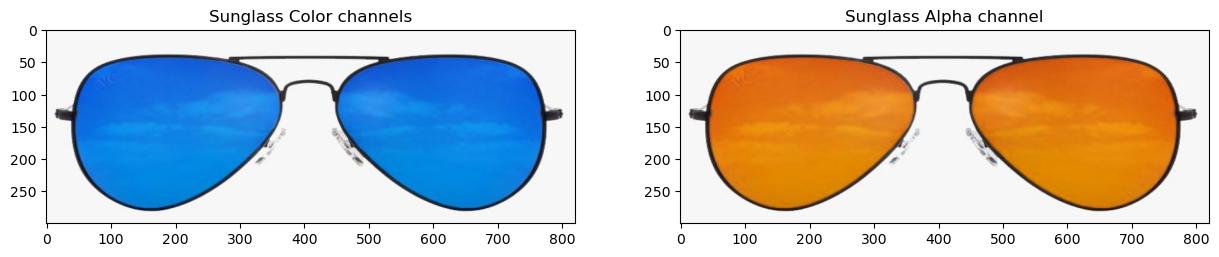

In [10]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

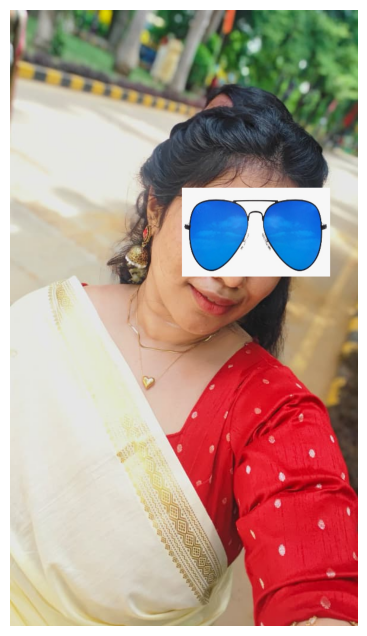

In [31]:

import cv2
import matplotlib.pyplot as plt

# Load the images
faceImage = cv2.imread("sheetal.jpeg")
glassImage = cv2.imread("glass.jpg")

# Check if images loaded correctly
if faceImage is None:
    raise FileNotFoundError("Could not find sheetal.jpeg")

if glassImage is None:
    raise FileNotFoundError("Could not find glass.jpg")

# Resize the glasses
glassBGR = cv2.resize(glassImage, (250, 150))

# Copy the face image
faceWithGlassesNaive = faceImage.copy()

# Adjust glasses position
x = 290  # Left/Right
y = 300 # Up/Down

# Get image dimensions
h, w = faceWithGlassesNaive.shape[:2]

# Ensure glasses stay within image boundaries
x = max(0, min(x, w - 1))
y = max(0, min(y, h - 1))

# Crop glasses to fit the available region
glass_crop = glassBGR[:min(170, h-y), :min(500, w-x)]

# Place the glasses
gh, gw = glass_crop.shape[:2]
faceWithGlassesNaive[y:y+gh, x:x+gw] = glass_crop

# Display the result
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(faceWithGlassesNaive, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


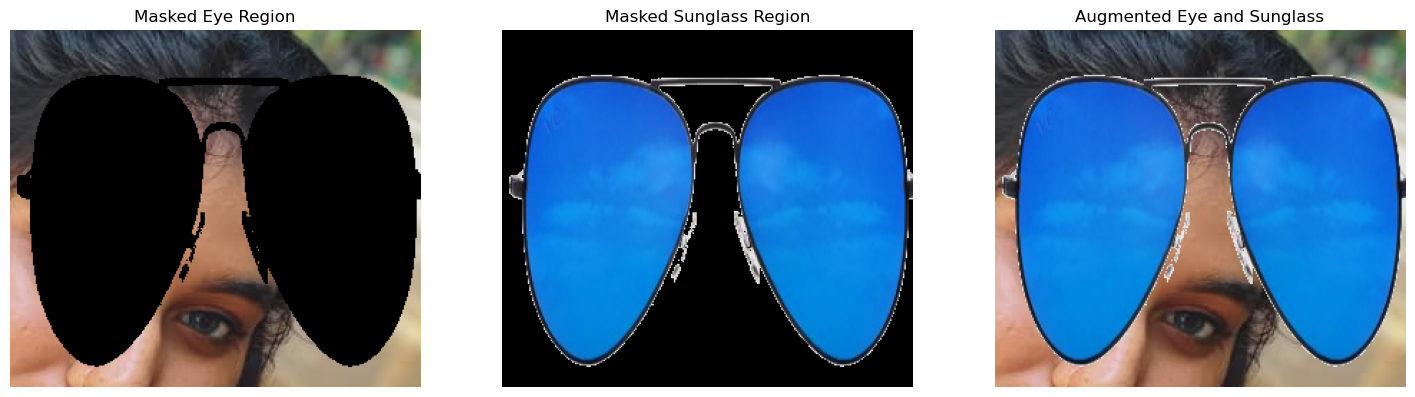

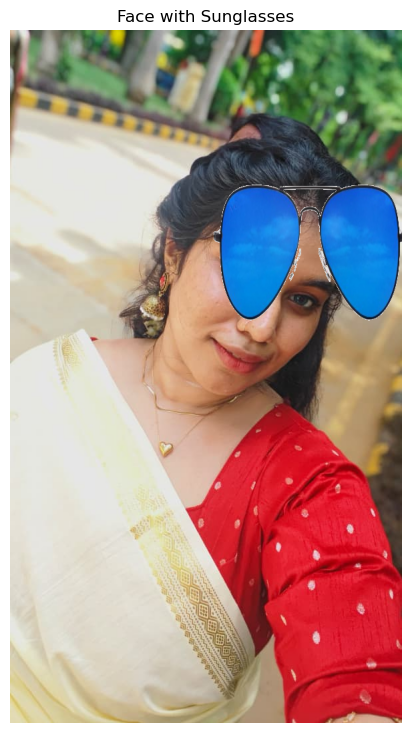

In [49]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load images
faceImage = cv2.imread("sheetal.jpeg")
glassImage = cv2.imread("glass.jpg")

# Resize glasses
w = 300
h = 250
glassBGR = cv2.resize(glassImage, (w, h))

# Create mask from white background
gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)
_, glassMask = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY_INV)

# Convert mask to 3 channels
glassMask = cv2.merge((glassMask, glassMask, glassMask))
glassMask = glassMask.astype(np.float32) / 255.0

# Copy face image
faceWithGlassesArithmetic = faceImage.copy()

# Position of glasses (adjust as needed)
x = 300
y = 200

# Get image dimensions
faceH, faceW = faceImage.shape[:2]

# Ensure glasses fit inside the face image
w = min(w, faceW - x)
h = min(h, faceH - y)

# Crop glasses and mask to the same dimensions
glassBGR = glassBGR[:h, :w].astype(np.float32)
glassMask = glassMask[:h, :w]

# Extract region of interest (ROI)
eyeROI = faceWithGlassesArithmetic[y:y+h, x:x+w].astype(np.float32)

# Arithmetic operations
maskedEye = eyeROI * (1 - glassMask)
maskedGlass = glassBGR * glassMask

eyeRoiFinal = maskedEye + maskedGlass
eyeRoiFinal = np.clip(eyeRoiFinal, 0, 255).astype(np.uint8)

# Display intermediate images
plt.figure(figsize=(18, 6))

plt.subplot(131)
plt.imshow(cv2.cvtColor(maskedEye.astype(np.uint8), cv2.COLOR_BGR2RGB))
plt.title("Masked Eye Region")
plt.axis("off")

plt.subplot(132)
plt.imshow(cv2.cvtColor(maskedGlass.astype(np.uint8), cv2.COLOR_BGR2RGB))
plt.title("Masked Sunglass Region")
plt.axis("off")

plt.subplot(133)
plt.imshow(cv2.cvtColor(eyeRoiFinal, cv2.COLOR_BGR2RGB))
plt.title("Augmented Eye and Sunglass")
plt.axis("off")

plt.show()

# Put result back into face
faceWithGlassesArithmetic[y:y+h, x:x+w] = eyeRoiFinal

# Display final result
plt.figure(figsize=(7, 9))
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.title("Face with Sunglasses")
plt.axis("off")
plt.show()


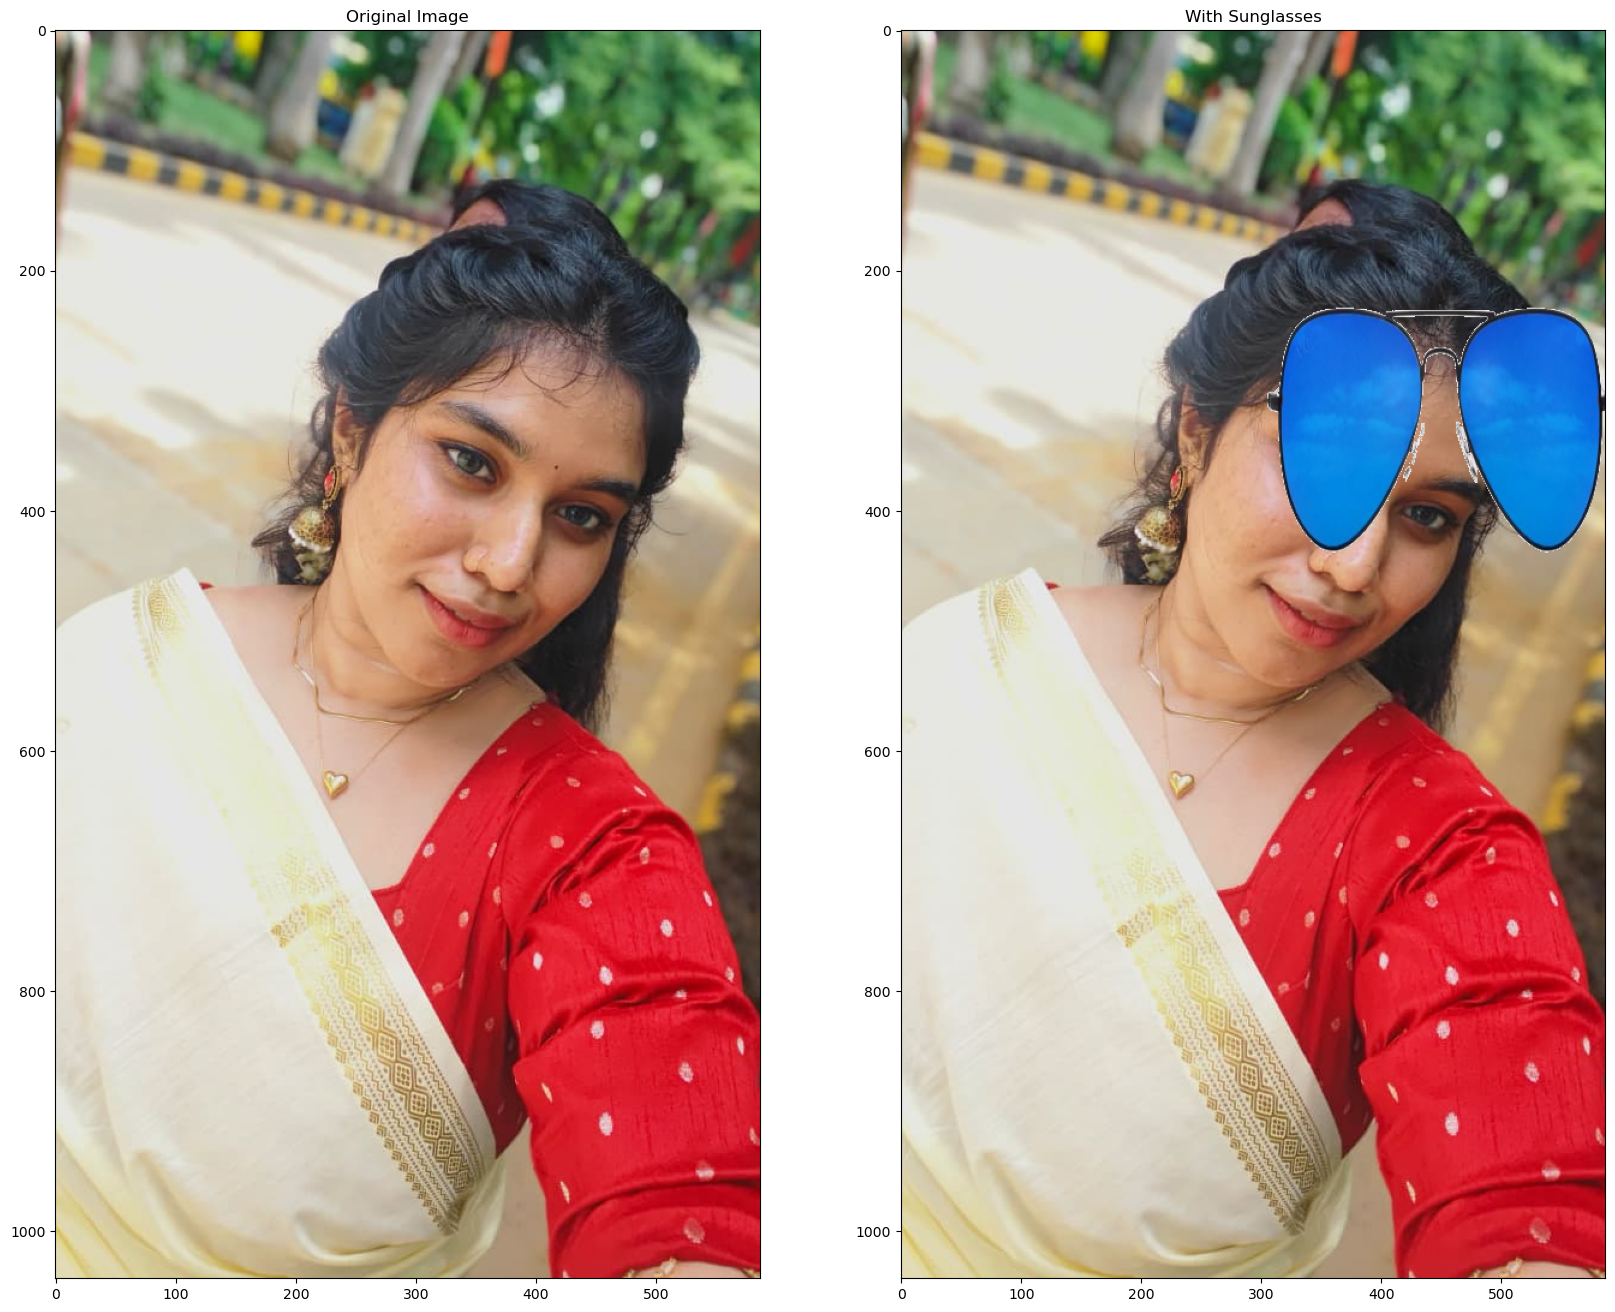

In [50]:
plt.figure(figsize=(20,20))

plt.subplot(121)
plt.imshow(faceImage[:,:,::-1])
plt.title("Original Image")

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:,:,::-1])
plt.title("With Sunglasses")

plt.show()